<a href="https://colab.research.google.com/github/salpimentel/Time-Series/blob/main/Copy_of_L00_Challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Challenge Repaso de Estadística**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

In [2]:
from google.colab import files
files.upload()

Saving US_change_full.csv to US_change_full.csv


{'US_change_full.csv': b'Date,Consumption,Income,Production,Savings,Unemployment\r\n01/01/1970,0.6185664,1.044801332,-2.452485527,5.299014071,0.9\r\n01/04/1970,0.451984019,1.225647192,-0.551459474,7.789893824,0.5\r\n01/07/1970,0.87287178,1.585153835,-0.358651752,7.403984066,0.5\r\n01/10/1970,-0.271847933,-0.239544865,-2.185690872,1.169898242,0.7\r\n01/01/1971,1.901344959,1.975924949,1.909764364,3.535666928,-0.1\r\n01/04/1971,0.914877346,1.445908528,0.901569522,5.874763572,-0.1\r\n01/07/1971,0.794109641,0.521149113,0.308030708,-0.406235341,0.1\r\n01/10/1971,1.645633164,1.159176094,2.291362138,-1.486258902,0\r\n01/01/1972,1.311189694,0.456856714,4.154294954,-4.291972196,-0.2\r\n01/04/1972,1.885777877,1.033389307,1.888672712,-4.692196362,-0.1\r\n01/07/1972,1.529333612,1.9262949,1.265411446,5.92345399,-0.2\r\n01/10/1972,2.319557542,3.929949222,3.439587472,16.07351412,-0.3\r\n01/01/1973,1.809282167,0.755642728,2.794145253,-4.758983188,-0.3\r\n01/04/1973,-0.045090607,0.84039233,0.832174484,8

In [3]:
df = pd.read_csv("/content/US_change_full.csv")
df

,Date,Consumption,Income,Production,Savings,Unemployment
0,01/01/1970,0.618566,1.044801,-2.452486,5.299014,0.9
1,01/04/1970,0.451984,1.225647,-0.551459,7.789894,0.5
2,01/07/1970,0.872872,1.585154,-0.358652,7.403984,0.5
3,01/10/1970,-0.271848,-0.239545,-2.185691,1.169898,0.7
4,01/01/1971,1.901345,1.975925,1.909764,3.535667,-0.1
...,...,...,...,...,...,...
193,01/04/2018,0.983112,0.661825,1.117424,-2.723974,0.0
194,01/07/2018,0.853181,0.806271,1.256722,-0.085686,-0.3
195,01/10/2018,0.356512,0.695142,0.948148,5.031337,0.2
196,01/01/2019,0.282885,1.100753,-0.488206,9.760287,-0.1


Realizar el mismo ejercicio ejecutado en el cuaderno Modelos de Regresión con el set de datos "US_change_full" con la variable independiente

$$y = Consumption$$

Elegir el modelo de regresión que mejor se ajuste utilizando las variables restantes

In [4]:
# Identificar columnas con valores nulos (NA)
null_columns = df.isna().sum()
print("Valores nulos por columna:")
print(null_columns[null_columns > 0] if (null_columns > 0).any() else "No hay valores nulos en el dataset.")

Valores nulos por columna:
No hay valores nulos en el dataset.


In [5]:
# Calcular la varianza de la columna Consumption
variance_consumption = df['Consumption'].var()
print(f"La varianza de la columna Consumption es: {variance_consumption}")

La varianza de la columna Consumption es: 0.40686924695097626


In [6]:
# Calcular la matriz de covarianza de las columnas numéricas
covariance_matrix = df.select_dtypes(include='number').cov()
display(covariance_matrix)

,Consumption,Income,Production,Savings,Unemployment
Consumption,0.406869,0.220377,0.513498,-1.958849,-0.123402
Income,0.220377,0.810707,0.368714,7.759070,-0.074223
Production,0.513498,0.368714,2.314504,-1.065057,-0.428899
Savings,-1.958849,7.759070,-1.065057,143.192915,0.465725
Unemployment,-0.123402,-0.074223,-0.428899,0.465725,0.134923


In [7]:
# Calcular la matriz de correlación de las columnas numéricas
correlation_matrix = df.select_dtypes(include='number').corr()
display(correlation_matrix)

,Consumption,Income,Production,Savings,Unemployment
Consumption,1.000000,0.383713,0.529154,-0.256633,-0.526687
Income,0.383713,1.000000,0.269171,0.720140,-0.224422
Production,0.529154,0.269171,1.000000,-0.058504,-0.767509
Savings,-0.256633,0.720140,-0.058504,1.000000,0.105956
Unemployment,-0.526687,-0.224422,-0.767509,0.105956,1.000000


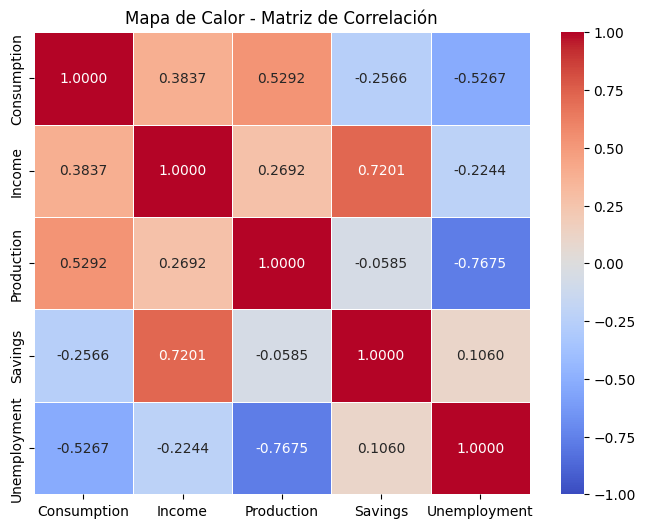

In [8]:
# Crear un mapa de calor para visualizar la matriz de correlación
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.4f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Mapa de Calor - Matriz de Correlación')
plt.show()

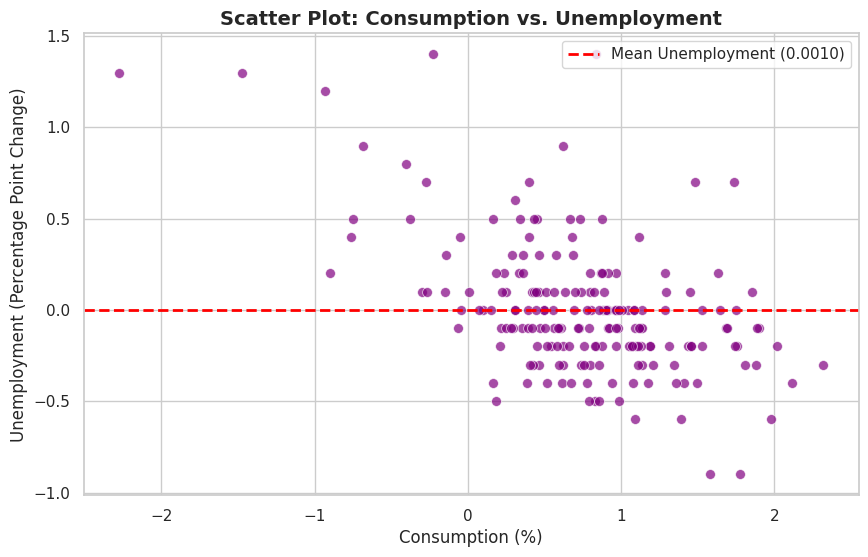

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the mean of Unemployment (y)
mean_unemployment = df['Unemployment'].mean()

# Set the plot style and size
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 6))

# Create the scatter plot
sns.scatterplot(data=df, x='Consumption', y='Unemployment', color='purple', alpha=0.7, s=50)

# Add the horizontal line at the mean of Unemployment
plt.axhline(mean_unemployment, color='red', linestyle='--', linewidth=2, label=f'Mean Unemployment ({mean_unemployment:.4f})')

# Add titles and labels
plt.title('Scatter Plot: Consumption vs. Unemployment', fontsize=14, fontweight='bold')
plt.xlabel('Consumption (%)', fontsize=12)
plt.ylabel('Unemployment (Percentage Point Change)', fontsize=12)
plt.legend(loc='upper right')

# Show the plot
plt.show()

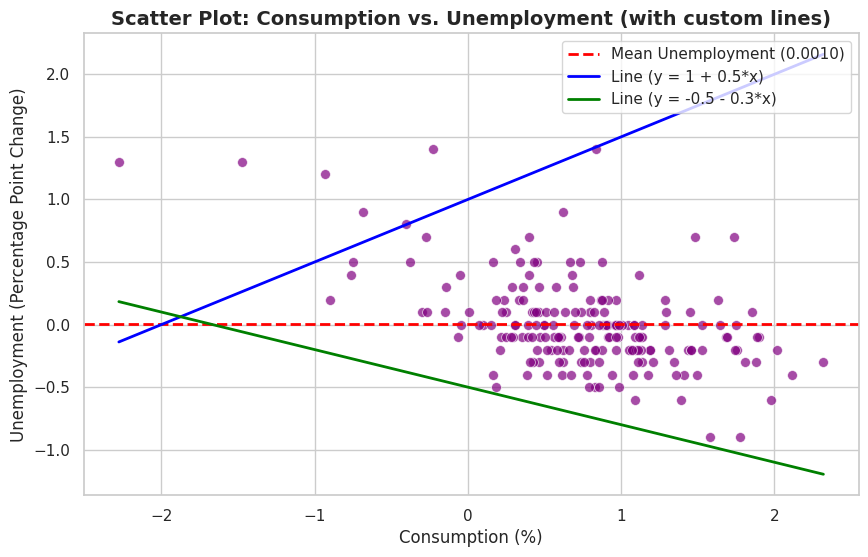

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the mean of Unemployment (y)
mean_unemployment = df['Unemployment'].mean()

# Generate x values spanning the range of Consumption
x_vals = np.linspace(df['Consumption'].min(), df['Consumption'].max(), 100)

# First line: intercept = 1, slope = 0.5
y_vals_1 = 1 + 0.5 * x_vals

# Second line: intercept = 0.5, slope = -0.3
y_vals_2 = -0.5 - 0.3 * x_vals

# Set the plot style and size
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 6))

# Create the scatter plot
sns.scatterplot(data=df, x='Consumption', y='Unemployment', color='purple', alpha=0.7, s=50)

# Add the horizontal line at the mean of Unemployment
plt.axhline(mean_unemployment, color='red', linestyle='--', linewidth=2, label=f'Mean Unemployment ({mean_unemployment:.4f})')

# Add the first custom line
plt.plot(x_vals, y_vals_1, color='blue', linestyle='-', linewidth=2, label='Line (y = 1 + 0.5*x)')

# Add the second custom line
plt.plot(x_vals, y_vals_2, color='green', linestyle='-', linewidth=2, label='Line (y = -0.5 - 0.3*x)')

# Add titles and labels
plt.title('Scatter Plot: Consumption vs. Unemployment (with custom lines)', fontsize=14, fontweight='bold')
plt.xlabel('Consumption (%)', fontsize=12)
plt.ylabel('Unemployment (Percentage Point Change)', fontsize=12)
plt.legend(loc='upper right')

# Show the plot
plt.show()

In [24]:
# Fit a linear regression model with x = Unemployment and y = Consumption
linear_model = smf.ols(formula='Consumption ~ Unemployment', data=df).fit()

# Display the regression summary results
print(linear_model.summary())

                            OLS Regression Results                            
Dep. Variable:            Consumption   R-squared:                       0.277
Model:                            OLS   Adj. R-squared:                  0.274
Method:                 Least Squares   F-statistic:                     75.24
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           1.59e-15
Time:                        17:41:07   Log-Likelihood:                -159.26
No. Observations:                 198   AIC:                             322.5
Df Residuals:                     196   BIC:                             329.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.7434      0.039     19.243   

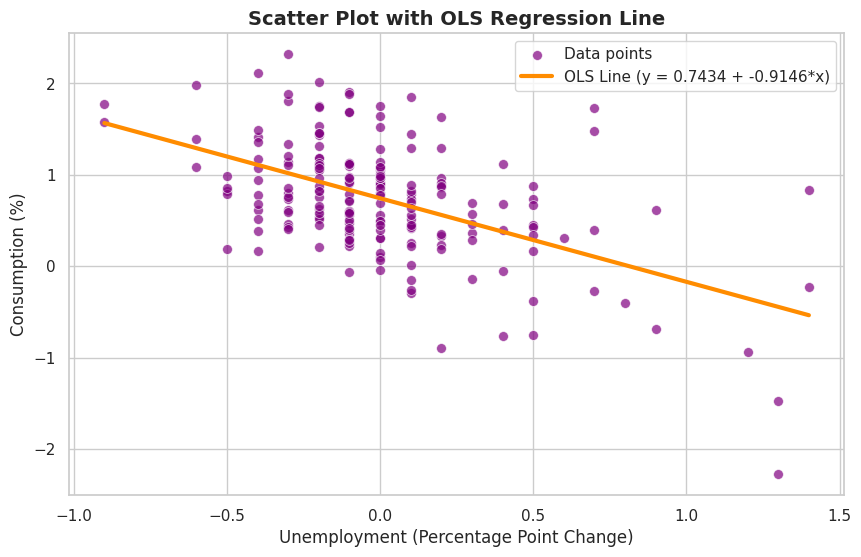

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Generate a range of x values for the regression line
x_line = np.linspace(df['Unemployment'].min(), df['Unemployment'].max(), 100)
# Predict y values using our fitted linear model
y_line = linear_model.predict(pd.DataFrame({'Unemployment': x_line}))

sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 6))

# Plot the data points
sns.scatterplot(data=df, x='Unemployment', y='Consumption', color='purple', alpha=0.7, s=50, label='Data points')

# Plot the OLS regression line
plt.plot(x_line, y_line, color='darkorange', linestyle='-', linewidth=3,
         label=f'OLS Line (y = {linear_model.params["Intercept"]:.4f} + {linear_model.params["Unemployment"]:.4f}*x)')

plt.title('Scatter Plot with OLS Regression Line', fontsize=14, fontweight='bold')
plt.xlabel('Unemployment (Percentage Point Change)', fontsize=12)
plt.ylabel('Consumption (%)', fontsize=12)
plt.legend(loc='upper right')
plt.show()

In [26]:
import itertools
import pandas as pd
import statsmodels.formula.api as smf

# Define the dependent variable and candidates for independent variables
dep_var = 'Consumption'
indep_vars = ['Income', 'Production', 'Savings', 'Unemployment']

# List to store results
results_list = []

# Generate all combinations of independent variables (from 1 to 4 variables)
for r in range(1, len(indep_vars) + 1):
    for combo in itertools.combinations(indep_vars, r):
        formula = f"{dep_var} ~ {' + '.join(combo)}"
        model = smf.ols(formula=formula, data=df).fit()

        results_list.append({
            'Variables': ', '.join(combo),
            'Num_Vars': r,
            'Formula': formula,
            'R_squared': model.rsquared,
            'Adj_R_squared': model.rsquared_adj,
            'AIC': model.aic,
            'BIC': model.bic
        })

# Convert to DataFrame and sort by Adjusted R-squared in descending order
all_models_df = pd.DataFrame(results_list).sort_values(by='Adj_R_squared', ascending=False).reset_index(drop=True)
display(all_models_df)

,Variables,Num_Vars,Formula,R_squared,Adj_R_squared,AIC,BIC
0,"Income, Production, Savings, Unemployment",4,Consumption ~ Income + Production + Savings + ...,0.768283,0.763481,103.319799,119.761134
1,"Income, Production, Savings",3,Consumption ~ Income + Production + Savings,0.764267,0.760621,104.722150,117.875218
2,"Income, Savings, Unemployment",3,Consumption ~ Income + Savings + Unemployment,0.763294,0.759634,105.537266,118.690334
3,"Income, Savings",2,Consumption ~ Income + Savings,0.737281,0.734586,124.182562,134.047363
4,"Income, Production, Unemployment",3,Consumption ~ Income + Production + Unemployment,0.375494,0.365836,297.625779,310.778847
5,"Production, Savings, Unemployment",3,Consumption ~ Production + Savings + Unemployment,0.359084,0.349173,302.761265,315.914333
6,"Income, Unemployment",2,Consumption ~ Income + Unemployment,0.351635,0.344985,303.049317,312.914118
7,"Income, Production",2,Consumption ~ Income + Production,0.342768,0.336027,305.738892,315.603693
8,"Production, Savings",2,Consumption ~ Production + Savings,0.331109,0.324248,309.220527,319.085328
9,"Savings, Unemployment",2,Consumption ~ Savings + Unemployment,0.318188,0.311195,313.008582,322.873384
